In [1]:
# conda env 'at3d_pure_k9'
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'

import sys
sys.path.append(str(PROJECT_ROOT))

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from src.utils.util import load_sensor_dict
from src.utils.util import save_sensor_dict

In [2]:
## INPUT
lut_file = PROJECT_ROOT / 'NK1990_1D_Retrieval' / 'LUT_I_V05.nc'
obs_file = INTERIM_DATA / 'AT3D_OBS_I_CAMP2Ex_RF17_default.nc'
# rte_grid_file = INTERIM_DATA / 'RTG_default.nc'

## OUTPUT
out_file = INTERIM_DATA / 'TAU1D_LUT_I_V05_AT3D_OBS_I_CAMP2Ex_RF17_default.nc'

In [3]:
# rte_grid = xr.load_dataset(rte_grid_file)
obs = load_sensor_dict(obs_file)
LUT = xr.load_dataset(lut_file)
assert np.all(np.diff(LUT.I.data) > 0), "LUT I not monotonic"

In [4]:
cam = obs['MISR']['sensor_list'][4]
measured_I = (cam.I.copy(deep=True)).data
measured_tau = np.zeros(measured_I.shape)
for i, m_I in enumerate(measured_I):
    measured_tau[i] = LUT.sel(I=m_I, method='nearest').tau.data
measured_tau[measured_tau <= np.min(LUT.tau.data)] = 0
cam['tau'] = (['nrays'], measured_tau)
save_sensor_dict(out_file, obs)

Saved sensors to: /data/gdi/b/johntl3/LundstromPub2025/data/interim/TAU1D_LUT_I_V05_AT3D_OBS_I_CAMP2Ex_RF17_default.nc


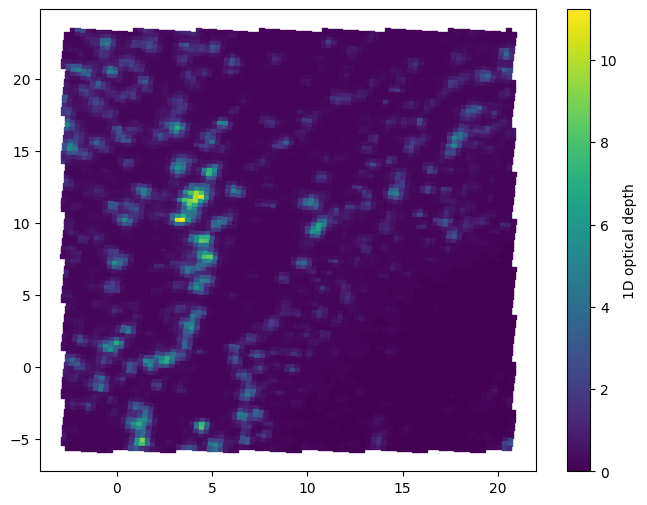

In [5]:
f, ax = plt.subplots(1, 1, figsize=(8,6))
# c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, norm=colors.LogNorm(vmin=0.1, vmax=10))
c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, vmin=0.0, vmax=None)
plt.colorbar(c, label='1D optical depth')